In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Student Marks Analyzer")
print("Libraries imported successfully!")

Student Marks Analyzer
Libraries imported successfully!


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generate sample monthly returns for 3 assets
np.random.seed(42)

months = 60

data = {
    "Equity": np.random.normal(0.012, 0.045, months),
    "Bonds": np.random.normal(0.005, 0.015, months),
    "Gold": np.random.normal(0.007, 0.025, months)
}

returns_df = pd.DataFrame(data)

print("Sample monthly returns generated successfully!")
display(returns_df.head())

Sample monthly returns generated successfully!


,Equity,Bonds,Gold
0,0.034352,-0.002188,0.026776
1,0.005778,0.002215,-0.015735
2,0.041146,-0.011595,0.042070
3,0.080536,-0.012943,-0.028046
4,0.001463,0.017188,0.021671


In [7]:
initial_investment = 100000

investment_years = 20

number_of_simulations = 10000

portfolio_weights = {
    "Equity": 0.60,
    "Bonds": 0.25,
    "Gold": 0.15
}

print("Portfolio Allocation")

for asset, weight in portfolio_weights.items():

    print(asset, ":", weight * 100, "%")

print(
    "Total Allocation:",
    sum(portfolio_weights.values()) * 100,
    "%"
)

Portfolio Allocation
Equity : 60.0 %
Bonds : 25.0 %
Gold : 15.0 %
Total Allocation: 100.0 %


In [8]:
weights = np.array(
    list(portfolio_weights.values())
)

asset_returns = returns_df[
    list(portfolio_weights.keys())
].values

portfolio_returns = asset_returns @ weights

average_monthly_return = np.mean(portfolio_returns)

monthly_volatility = np.std(
    portfolio_returns,
    ddof=1
)

annualized_return = (
    (1 + average_monthly_return) ** 12 - 1
)

annualized_volatility = monthly_volatility * np.sqrt(12)

print("========== PORTFOLIO STATISTICS ==========")

print(
    "Average Monthly Return:",
    round(average_monthly_return * 100, 3), "%"
)

print(
    "Monthly Volatility:",
    round(monthly_volatility * 100, 3), "%"
)

print(
    "Annualized Return:",
    round(annualized_return * 100, 3), "%"
)

print(
    "Annualized Volatility:",
    round(annualized_volatility * 100, 3), "%"
)

========== PORTFOLIO STATISTICS ==========
Average Monthly Return: 0.566 %
Monthly Volatility: 2.584 %
Annualized Return: 7.001 %
Annualized Volatility: 8.952 %


In [9]:
months = investment_years * 12

np.random.seed(42)

simulated_returns = np.random.normal(
    loc=average_monthly_return,
    scale=monthly_volatility,
    size=(number_of_simulations, months)
)

# Prevent returns below -100%
simulated_returns = np.maximum(
    simulated_returns,
    -0.999
)

# Calculate monthly growth factors
growth_factors = 1 + simulated_returns

# Store portfolio values
portfolio_paths = np.zeros(
    (number_of_simulations, months + 1)
)

portfolio_paths[:, 0] = initial_investment

# Calculate cumulative portfolio growth
portfolio_paths[:, 1:] = (
    initial_investment *
    np.cumprod(growth_factors, axis=1)
)

print("Monte Carlo Simulation Completed!")

print("Total Simulations:", number_of_simulations)

print("Investment Period:", investment_years, "years")

Monte Carlo Simulation Completed!
Total Simulations: 10000
Investment Period: 20 years


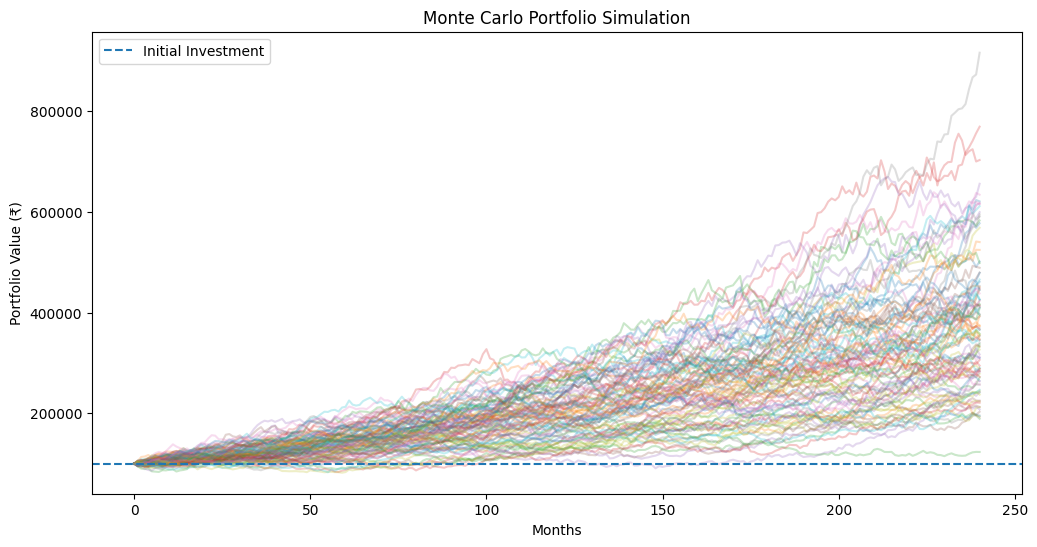

In [10]:
plt.figure(figsize=(12, 6))

for i in range(100):

    plt.plot(
        portfolio_paths[i],
        alpha=0.25
    )

plt.title("Monte Carlo Portfolio Simulation")

plt.xlabel("Months")

plt.ylabel("Portfolio Value (₹)")

plt.axhline(
    initial_investment,
    linestyle="--",
    label="Initial Investment"
)

plt.legend()

plt.show()

In [11]:
final_values = portfolio_paths[:, -1]

mean_value = np.mean(final_values)

median_value = np.median(final_values)

minimum_value = np.min(final_values)

maximum_value = np.max(final_values)

percentile_5 = np.percentile(final_values, 5)

percentile_25 = np.percentile(final_values, 25)

percentile_75 = np.percentile(final_values, 75)

percentile_95 = np.percentile(final_values, 95)

probability_of_loss = np.mean(
    final_values < initial_investment
)

print("========== SIMULATION RESULTS ==========")

print("Initial Investment: ₹", initial_investment)

print("Mean Final Value: ₹", round(mean_value, 2))

print("Median Final Value: ₹", round(median_value, 2))

print("Minimum Value: ₹", round(minimum_value, 2))

print("Maximum Value: ₹", round(maximum_value, 2))

print("5th Percentile: ₹", round(percentile_5, 2))

print("25th Percentile: ₹", round(percentile_25, 2))

print("75th Percentile: ₹", round(percentile_75, 2))

print("95th Percentile: ₹", round(percentile_95, 2))

print(
    "Probability of Loss:",
    round(probability_of_loss * 100, 2),
    "%"
)

========== SIMULATION RESULTS ==========
Initial Investment: ₹ 100000
Mean Final Value: ₹ 385052.12
Median Final Value: ₹ 358437.49
Minimum Value: ₹ 81137.73
Maximum Value: ₹ 1518853.55
5th Percentile: ₹ 185703.62
25th Percentile: ₹ 274893.63
75th Percentile: ₹ 461062.12
95th Percentile: ₹ 681741.46
Probability of Loss: 0.07 %


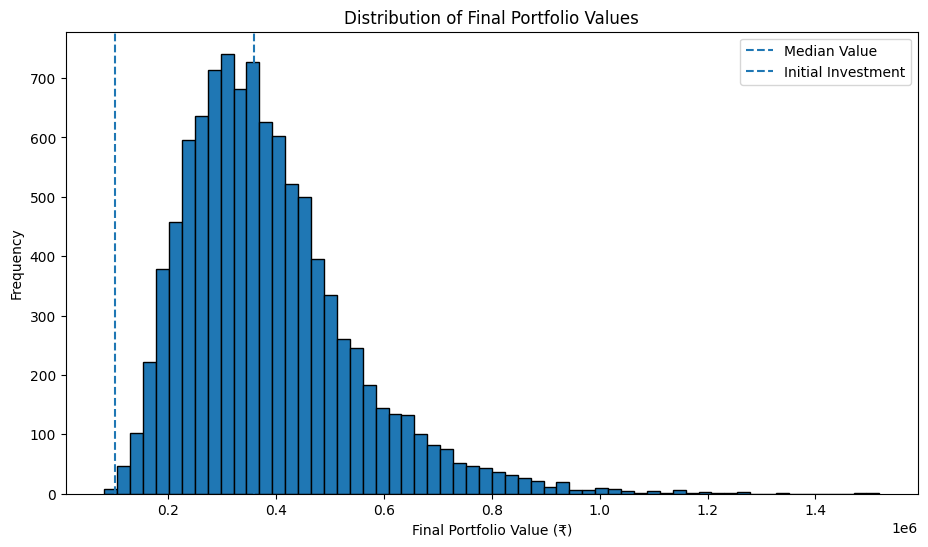

In [12]:
plt.figure(figsize=(11, 6))

plt.hist(
    final_values,
    bins=60,
    edgecolor="black"
)

plt.axvline(
    median_value,
    linestyle="--",
    label="Median Value"
)

plt.axvline(
    initial_investment,
    linestyle="--",
    label="Initial Investment"
)

plt.title("Distribution of Final Portfolio Values")

plt.xlabel("Final Portfolio Value (₹)")

plt.ylabel("Frequency")

plt.legend()

plt.show()

In [13]:
allocations = {
    "Conservative": [0.20, 0.60, 0.20],
    "Balanced": [0.60, 0.25, 0.15],
    "Aggressive": [0.80, 0.10, 0.10]
}

scenario_results = {}

for name, weights in allocations.items():

    weights = np.array(weights)

    monthly_returns = asset_returns @ weights

    mean = np.mean(monthly_returns)

    volatility = np.std(monthly_returns, ddof=1)

    simulated = np.random.normal(
        mean,
        volatility,
        size=(number_of_simulations, months)
    )

    simulated = np.maximum(simulated, -0.999)

    final = initial_investment * np.prod(
        1 + simulated,
        axis=1
    )

    scenario_results[name] = {
        "Average Final Value": np.mean(final),
        "Median Final Value": np.median(final),
        "Probability of Loss": np.mean(
            final < initial_investment
        ) * 100
    }

scenario_df = pd.DataFrame(scenario_results).T

display(scenario_df.round(2))

,Average Final Value,Median Final Value,Probability of Loss
Conservative,404009.19,393806.65,0.00
Balanced,387143.20,358264.76,0.04
Aggressive,368611.71,323742.48,1.28


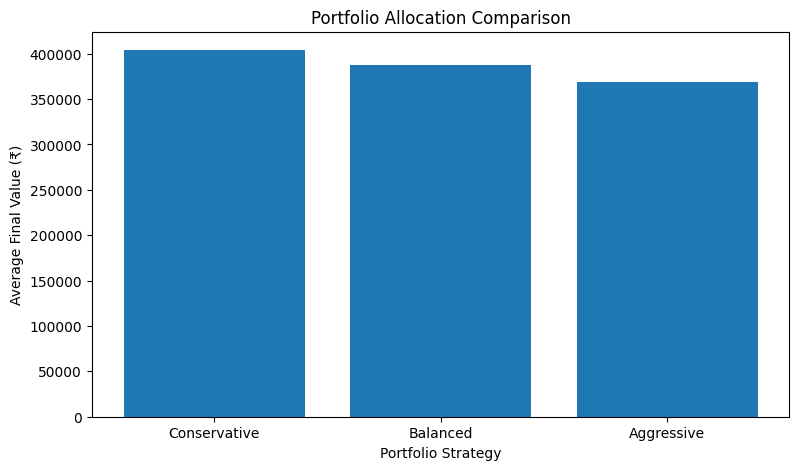

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    scenario_df.index,
    scenario_df["Average Final Value"]
)

plt.title("Portfolio Allocation Comparison")

plt.xlabel("Portfolio Strategy")

plt.ylabel("Average Final Value (₹)")

plt.show()

In [15]:
os.makedirs("monte_carlo_output", exist_ok=True)

# Save simulation paths
simulation_df = pd.DataFrame(
    portfolio_paths
)

simulation_df.to_csv(
    "monte_carlo_output/simulation_results.csv",
    index=False
)

# Save scenario comparison
scenario_df.to_csv(
    "monte_carlo_output/scenario_comparison.csv"
)

# Save summary
summary = pd.DataFrame({
    "Metric": [
        "Initial Investment",
        "Mean Final Value",
        "Median Final Value",
        "5th Percentile",
        "95th Percentile",
        "Probability of Loss"
    ],

    "Value": [
        initial_investment,
        mean_value,
        median_value,
        percentile_5,
        percentile_95,
        probability_of_loss * 100
    ]
})

summary.to_csv(
    "monte_carlo_output/summary_report.csv",
    index=False
)

print("All reports exported successfully!")

All reports exported successfully!


In [16]:
import shutil
from google.colab import files

shutil.make_archive(
    "monte_carlo_portfolio_project",
    "zip",
    "monte_carlo_output"
)

files.download(
    "monte_carlo_portfolio_project.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>